# HW4-2 CIFAR-10 CNN

使用 CIFAR-10 資料集建立 CNN，進行 10 種圖片分類。

## 1. 匯入套件

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras.datasets import cifar10
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, Conv2D, MaxPooling2D, Flatten, Dense, Dropout
from tensorflow.keras.utils import to_categorical
from ipywidgets import interact_manual, IntSlider

np.random.seed(42)
tf.random.set_seed(42)

## 2. 讀取 CIFAR-10 資料

圖片大小是 32 × 32，包含 RGB 三個色彩通道。

In [2]:
(x_train, y_train), (x_test, y_test) = cifar10.load_data()

class_names = [
    "airplane", "automobile", "bird", "cat", "deer",
    "dog", "frog", "horse", "ship", "truck"
]

print("訓練圖片：", x_train.shape)
print("訓練標籤：", y_train.shape)
print("測試圖片：", x_test.shape)
print("測試標籤：", y_test.shape)

170498071/170498071 ━━━━━━━━━━━━━━━━━━━━ 1995s 12us/step
訓練圖片： (50000, 32, 32, 3)
訓練標籤： (50000, 1)
測試圖片： (10000, 32, 32, 3)
測試標籤： (10000, 1)


## 3. 訓練圖片

顯示訓練圖片與正確的類別名稱。

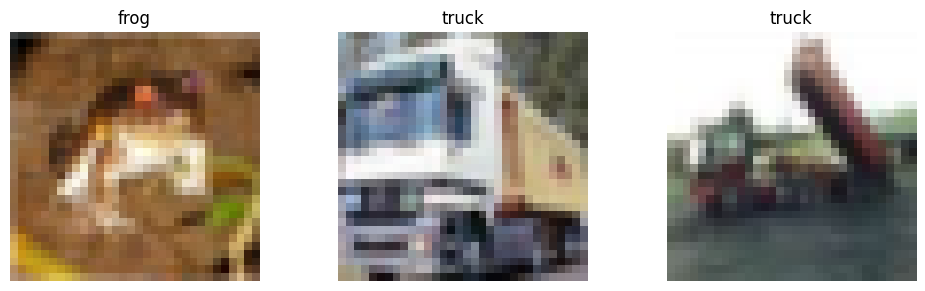

In [3]:
plt.figure(figsize=(10, 3))
for i in range(3):
    plt.subplot(1, 3, i + 1)
    plt.imshow(x_train[i])
    plt.title(class_names[int(y_train[i, 0])])
    plt.axis("off")
plt.tight_layout()
plt.show()

## 4. 資料預處理

圖片除以 255 進行正規化，標籤使用 one-hot encoding。

In [4]:
x_train_norm = x_train.astype("float32") / 255.0
x_test_norm = x_test.astype("float32") / 255.0

y_train_onehot = to_categorical(y_train.reshape(-1), 10)
y_test_onehot = to_categorical(y_test.reshape(-1), 10)

print("x_train_norm：", x_train_norm.shape)
print("x_test_norm：", x_test_norm.shape)
print("y_train_onehot：", y_train_onehot.shape)
print("y_test_onehot：", y_test_onehot.shape)

x_train_norm： (50000, 32, 32, 3)
x_test_norm： (10000, 32, 32, 3)
y_train_onehot： (50000, 10)
y_test_onehot： (10000, 10)


## 5. 建立 CNN 模型

使用兩組卷積與池化層，加入 Dropout，最後以全連接層分類。

In [5]:
model = Sequential([
    Input(shape=(32, 32, 3)),
    Conv2D(32, (5, 5), padding="same", activation="relu"),
    Dropout(0.25),
    MaxPooling2D(pool_size=(2, 2)),
    Conv2D(64, (3, 3), padding="same", activation="relu"),
    Dropout(0.25),
    MaxPooling2D(pool_size=(2, 2)),
    Flatten(),
    Dropout(0.25),
    Dense(1024, activation="relu"),
    Dropout(0.25),
    Dense(10, activation="softmax")
])

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 32, 32, 32)     │         2,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 32, 32, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 16, 16, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 8, 8, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 4096)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 4096)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 1024)           │     4,195,328 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 1024)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │        10,250 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,226,506 (16.12 MB)

 Trainable params: 4,226,506 (16.12 MB)

 Non-trainable params: 0 (0.00 B)

## 6. 各層 shape 與參數量

批次大小為 128，輸入 shape：`(128, 32, 32, 3)`。卷積使用 `padding="same"`。

卷積層參數 = `(kernel高 × kernel寬 × 輸入通道 + 1) × filter數`。

Dense 參數 = `(輸入數量 + 1) × 神經元數`。Dropout、池化層與 Flatten 的參數量都是 0。

In [6]:
batch_size = 128
print("批次 input shape：", (batch_size, 32, 32, 3))

for layer in model.layers:
    shape = tuple(batch_size if d is None else int(d) for d in layer.output.shape)
    print(layer.name, "output shape:", shape, "params:", layer.count_params())

print("模型總參數：", model.count_params())

批次 input shape： (128, 32, 32, 3)
conv2d output shape: (128, 32, 32, 32) params: 2432
dropout output shape: (128, 32, 32, 32) params: 0
max_pooling2d output shape: (128, 16, 16, 32) params: 0
conv2d_1 output shape: (128, 16, 16, 64) params: 18496
dropout_1 output shape: (128, 16, 16, 64) params: 0
max_pooling2d_1 output shape: (128, 8, 8, 64) params: 0
flatten output shape: (128, 4096) params: 0
dropout_2 output shape: (128, 4096) params: 0
dense output shape: (128, 1024) params: 4195328
dropout_3 output shape: (128, 1024) params: 0
dense_1 output shape: (128, 10) params: 10250
模型總參數： 4226506


### 參數數量計算

In [7]:
print("Conv2D(32): (5×5×3+1)×32 =", (5*5*3+1)*32)
print("Conv2D(64): (3×3×32+1)×64 =", (3*3*32+1)*64)
print("Dense(1024): (8×8×64+1)×1024 =", (8*8*64+1)*1024)
print("Dense(10): (1024+1)×10 =", (1024+1)*10)
print("參數總數：", (5*5*3+1)*32 + (3*3*32+1)*64 + (8*8*64+1)*1024 + (1024+1)*10)

Conv2D(32): (5×5×3+1)×32 = 2432
Conv2D(64): (3×3×32+1)×64 = 18496
Dense(1024): (8×8×64+1)×1024 = 4195328
Dense(10): (1024+1)×10 = 10250
參數總數： 4226506


## 7. 編譯與訓練

`categorical_crossentropy`、`adam`，訓練 20 個 epochs，每批 128 筆；訓練資料的 20% 作為驗證資料。

In [8]:
model.compile(
    loss="categorical_crossentropy",
    optimizer="adam",
    metrics=["accuracy"]
)

history = model.fit(
    x_train_norm,
    y_train_onehot,
    validation_split=0.2,
    epochs=20,
    batch_size=128,
    verbose=1
)

Epoch 1/20
313/313 ━━━━━━━━━━━━━━━━━━━━ 162s 502ms/step - accuracy: 0.4390 - loss: 1.5557 - val_accuracy: 0.5692 - val_loss: 1.3526
Epoch 2/20
313/313 ━━━━━━━━━━━━━━━━━━━━ 192s 473ms/step - accuracy: 0.5724 - loss: 1.2044 - val_accuracy: 0.6171 - val_loss: 1.1761
Epoch 3/20
313/313 ━━━━━━━━━━━━━━━━━━━━ 201s 472ms/step - accuracy: 0.6291 - loss: 1.0505 - val_accuracy: 0.6512 - val_loss: 1.0751
Epoch 4/20
313/313 ━━━━━━━━━━━━━━━━━━━━ 204s 478ms/step - accuracy: 0.6719 - loss: 0.9321 - val_accuracy: 0.6595 - val_loss: 0.9985
Epoch 5/20
313/313 ━━━━━━━━━━━━━━━━━━━━ 147s 468ms/step - accuracy: 0.7078 - loss: 0.8340 - val_accuracy: 0.6846 - val_loss: 0.9350
Epoch 6/20
313/313 ━━━━━━━━━━━━━━━━━━━━ 201s 467ms/step - accuracy: 0.7380 - loss: 0.7482 - val_accuracy: 0.6820 - val_loss: 0.9147
Epoch 7/20
313/313 ━━━━━━━━━━━━━━━━━━━━ 206s 481ms/step - accuracy: 0.7674 - loss: 0.6654 - val_accuracy: 0.6976 - val_loss: 0.8679
Epoch 8/20
313/313 ━━━━━━━━━━━━━━━━━━━━ 201s 478ms/step - accuracy: 0.7922 -

## 8. Accuracy 與 Loss

比較訓練資料和驗證資料的變化，觀察是否有 overfitting。

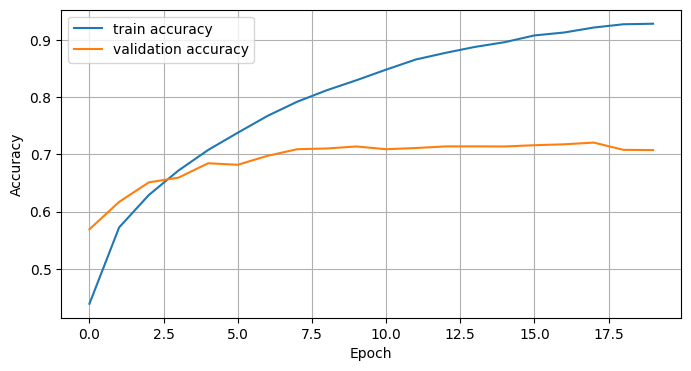

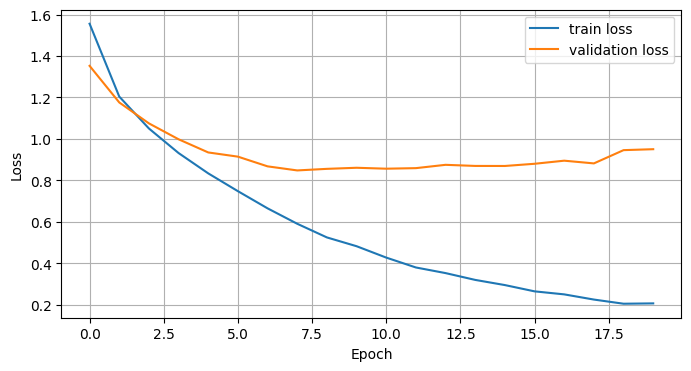

In [9]:
plt.figure(figsize=(8, 4))
plt.plot(history.history["accuracy"], label="train accuracy")
plt.plot(history.history["val_accuracy"], label="validation accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.grid()
plt.show()

plt.figure(figsize=(8, 4))
plt.plot(history.history["loss"], label="train loss")
plt.plot(history.history["val_loss"], label="validation loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid()
plt.show()

### Overfitting 觀察

In [10]:
best_epoch = int(np.argmax(history.history["val_accuracy"])) + 1
print("最高 validation accuracy：", round(max(history.history["val_accuracy"]), 4))
print("出現在第", best_epoch, "個 epoch")
print("最後 train accuracy：", round(history.history["accuracy"][-1], 4))
print("最後 validation accuracy：", round(history.history["val_accuracy"][-1], 4))

if history.history["loss"][-1] < history.history["loss"][best_epoch - 1] and history.history["val_loss"][-1] > history.history["val_loss"][best_epoch - 1]:
    print("後期 train loss 下降、validation loss 上升，可能有 overfitting。")
else:
    print("可對照上面的 loss 與 accuracy 曲線觀察 overfitting。")

最高 validation accuracy： 0.7208
出現在第 18 個 epoch
最後 train accuracy： 0.9287
最後 validation accuracy： 0.7077
後期 train loss 下降、validation loss 上升，可能有 overfitting。


## 9. 測試資料評估

以全部 10000 筆測試資料評估。

In [11]:
test_loss, test_accuracy = model.evaluate(x_test_norm, y_test_onehot, verbose=0)
print("Test loss:", test_loss)
print("Test accuracy:", test_accuracy)
print("Test accuracy (%):", test_accuracy * 100)

Test loss: 0.9741506576538086
Test accuracy: 0.7023000121116638
Test accuracy (%): 70.23000121116638


## 10. 測試資料預測

對全部測試資料預測，並顯示預測與正確的類別名稱。

79/79 ━━━━━━━━━━━━━━━━━━━━ 7s 83ms/step
測試 input shape: (10000, 32, 32, 3)
預測 output shape: (10000, 10)


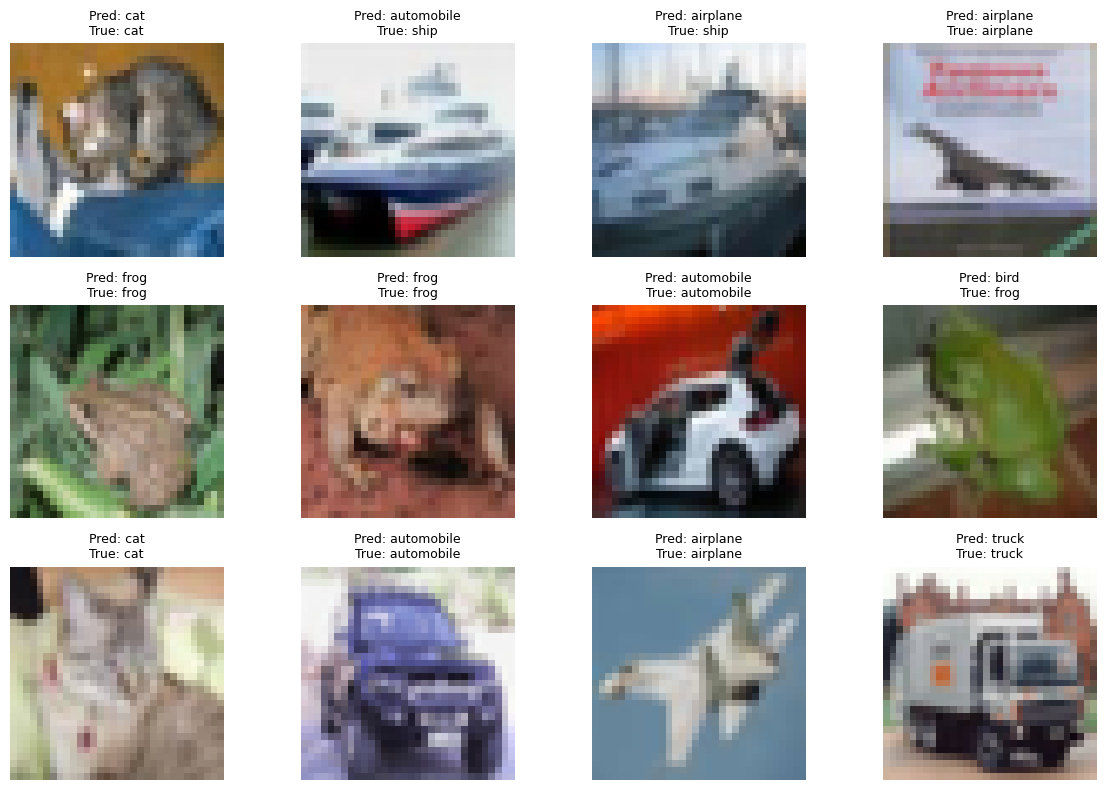

In [12]:
prediction = model.predict(x_test_norm, batch_size=128)
predicted_labels = np.argmax(prediction, axis=1)
true_labels = y_test.reshape(-1)

print("測試 input shape:", x_test_norm.shape)
print("預測 output shape:", prediction.shape)

plt.figure(figsize=(12, 8))
for i in range(12):
    plt.subplot(3, 4, i + 1)
    plt.imshow(x_test[i])
    plt.title(
        "Pred: " + class_names[predicted_labels[i]] + "\nTrue: " + class_names[true_labels[i]],
        fontsize=9
    )
    plt.axis("off")
plt.tight_layout()
plt.show()

## 11. Confusion Matrix

[[809  23  66  12   5   2  16  10  27  30]
 [ 19 841  17  12   4   5  21   1  12  68]
 [ 66   4 663  45  55  35  98  23   6   5]
 [ 32  13 105 448  56 162 139  31   5   9]
 [ 30   3 112  58 584  25 128  53   5   2]
 [ 21   4  74 166  39 577  73  37   2   7]
 [  8   2  44  34  12   9 883   3   2   3]
 [ 19   3  44  34  43  55  26 764   0  12]
 [113  55  28  16   8   8  18   6 721  27]
 [ 50 115  14  22   8   7  24  14  13 733]]


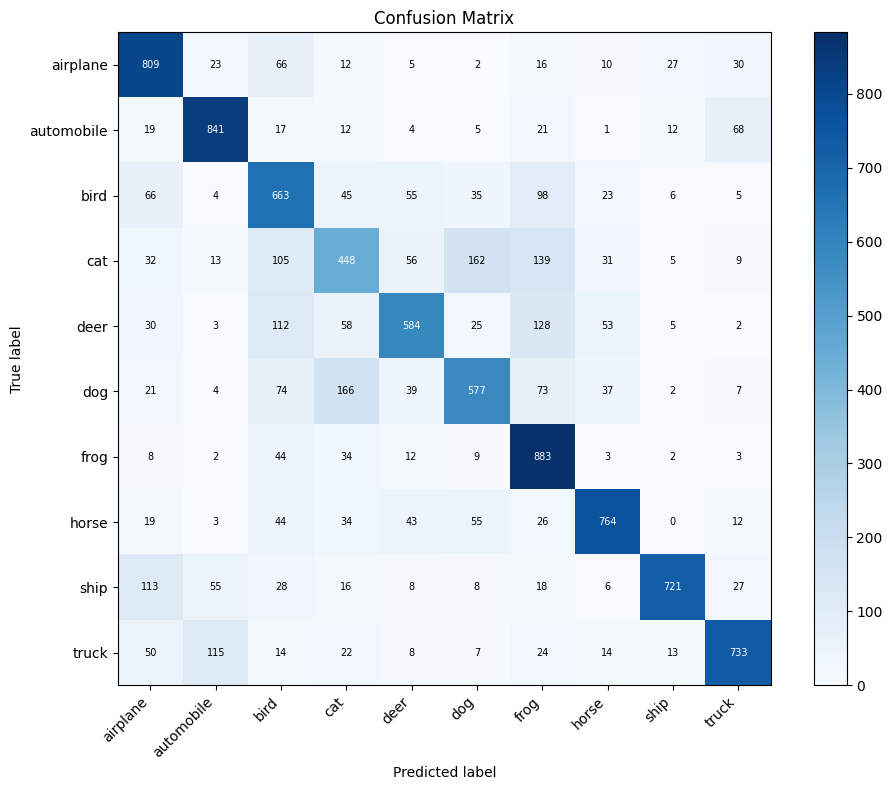

In [13]:
cm = tf.math.confusion_matrix(true_labels, predicted_labels, num_classes=10).numpy()
print(cm)

plt.figure(figsize=(10, 8))
plt.imshow(cm, cmap="Blues")
plt.colorbar()
plt.xticks(range(10), class_names, rotation=45, ha="right")
plt.yticks(range(10), class_names)
plt.xlabel("Predicted label")
plt.ylabel("True label")
plt.title("Confusion Matrix")
for i in range(10):
    for j in range(10):
        plt.text(j, i, cm[i, j], ha="center", va="center", fontsize=7,
                 color="white" if cm[i, j] > cm.max() / 2 else "black")
plt.tight_layout()
plt.show()

## 12. 儲存完整模型

將模型儲存成 `.keras` 檔。

In [14]:
model.save("cifar10_cnn_hw4_2.keras")
print("模型已儲存：cifar10_cnn_hw4_2.keras")

模型已儲存：cifar10_cnn_hw4_2.keras


## 13. interact_manual 預測

輸入測試圖片的編號，按下按鈕查看預測結果。

In [15]:
def show_prediction(index):
    plt.figure(figsize=(4, 4))
    plt.imshow(x_test[index])
    plt.axis("off")
    plt.title("Pred: " + class_names[predicted_labels[index]] +
              "\nTrue: " + class_names[true_labels[index]])
    plt.show()
    print("預測信心度：", round(float(np.max(prediction[index])) * 100, 2), "%")

interact_manual(show_prediction, index=IntSlider(value=0, min=0, max=9999, step=1, description="圖片編號"))

interactive(children=(IntSlider(value=0, description='圖片編號', max=9999), Button(description='Run Interact', sty…

<function __main__.show_prediction(index)>

## 14. 比較模型結果

HW4-1 採用兩層卷積、兩層池化與 128 個神經元的 Dense 層。

HW4-2 在卷積及全連接層之間增加 Dropout，並將全連接層改為 1024 個神經元。

In [16]:
hw41_test_accuracy = 0.6396999955177307
hw41_test_loss = 1.569158911705017
hw41_total_params = 545098

print("HW4-1 測試準確率：", round(hw41_test_accuracy * 100, 2), "%")
print("HW4-2 測試準確率：", round(test_accuracy * 100, 2), "%")
print("準確率差距：", round((test_accuracy - hw41_test_accuracy) * 100, 2), "個百分點")
print("HW4-1 Test loss：", round(hw41_test_loss, 4))
print("HW4-2 Test loss：", round(test_loss, 4))
print("HW4-1 參數量：", hw41_total_params)
print("HW4-2 參數量：", model.count_params())
print("HW4-2 最後 train accuracy：", round(history.history["accuracy"][-1], 4))
print("HW4-2 最後 validation accuracy：", round(history.history["val_accuracy"][-1], 4))

HW4-1 測試準確率： 63.97 %
HW4-2 測試準確率： 70.23 %
準確率差距： 6.26 個百分點
HW4-1 Test loss： 1.5692
HW4-2 Test loss： 0.9742
HW4-1 參數量： 545098
HW4-2 參數量： 4226506
HW4-2 最後 train accuracy： 0.9287
HW4-2 最後 validation accuracy： 0.7077


## 15. 結果

比較兩個 CNN 模型的測試準確率、loss、參數量及訓練曲線，觀察 Dropout 加入後的差異。